Check Environment + Install Required Libraries

In [ ]:
!pip install -q transformers datasets accelerate evaluate scikit-learn

import torch
import transformers
import datasets
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.5 MB/s eta 0:00:00
PyTorch: 2.11.0+cu128
Transformers: 5.13.1
Datasets: 4.0.0
Scikit-learn: 1.6.1

GPU Available: True
GPU: Tesla T4


Upload Dataset

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("Model final dataset.csv")

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Saving Model final dataset.csv to Model final dataset.csv
Dataset Shape: (15000, 2)

Columns:
['Sentences', 'Labels']

First 5 rows:


,Sentences,Labels
0,"We were missing a dwarf in the team, and now w...",0
1,useless guy,0
2,You are so rude!,0
3,Where does the goat live?,0
4,Why are you barking like a dog?,0


Shuffle and Split Dataset

In [ ]:
from sklearn.model_selection import train_test_split

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset shuffled successfully!\n")

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["Labels"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Labels"],
    random_state=42
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining label distribution:")
print(train_df["Labels"].value_counts().sort_index())

print("\nValidation label distribution:")
print(val_df["Labels"].value_counts().sort_index())

print("\nTesting label distribution:")
print(test_df["Labels"].value_counts().sort_index())

Dataset shuffled successfully!

Training samples: 12000
Validation samples: 1500
Testing samples: 1500

Training label distribution:
Labels
0    2400
1    2400
2    2400
3    2400
4    2400
Name: count, dtype: int64

Validation label distribution:
Labels
0    300
1    300
2    300
3    300
4    300
Name: count, dtype: int64

Testing label distribution:
Labels
0    300
1    300
2    300
3    300
4    300
Name: count, dtype: int64


Load RoBERTa Tokenizer

In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("RoBERTa tokenizer loaded successfully!")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model length:", tokenizer.model_max_length)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

RoBERTa tokenizer loaded successfully!
Model: roberta-base
Vocabulary size: 50265
Maximum model length: 512


Tokenize the Dataset

In [ ]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

train_dataset = train_dataset.rename_column("Labels", "labels")
val_dataset = val_dataset.rename_column("Labels", "labels")
test_dataset = test_dataset.rename_column("Labels", "labels")

def tokenize_function(examples):

    texts = [str(text) for text in examples["Sentences"]]

    return tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

print("Tokenization completed successfully!")

print(train_dataset[0])

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Tokenization completed successfully!
{'Sentences': 'Why didnâ€™t anyone start impeachments on half of them yet', 'labels': 4, '__index_level_0__': 1677, 'input_ids': [0, 7608, 399, 3695, 10851, 13445, 90, 1268, 386, 19828, 1488, 2963, 15, 457, 9, 106, 648, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


Prepare Dataset for Training

In [ ]:
columns_to_remove = []

if "Sentences" in train_dataset.column_names:
    columns_to_remove.append("Sentences")

if "__index_level_0__" in train_dataset.column_names:
    columns_to_remove.append("__index_level_0__")

if len(columns_to_remove) > 0:
    train_dataset = train_dataset.remove_columns(columns_to_remove)
    val_dataset = val_dataset.remove_columns(columns_to_remove)
    test_dataset = test_dataset.remove_columns(columns_to_remove)



train_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)

val_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)

test_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)


print("Training columns:", train_dataset.column_names)
print("Validation columns:", val_dataset.column_names)
print("Testing columns:", test_dataset.column_names)

Training columns: ['labels', 'input_ids', 'attention_mask']
Validation columns: ['labels', 'input_ids', 'attention_mask']
Testing columns: ['labels', 'input_ids', 'attention_mask']


Load RoBERTa Model

In [ ]:
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "roberta-base"

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
)

print("RoBERTa model loaded successfully!")
print("Model:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa model loaded successfully!
Model: roberta-base
Number of labels: 5


Configure Training Arguments

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./roberta_results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="eval_loss",

    logging_dir="./logs",
    logging_steps=100,

    report_to="none"
)

print("Training arguments configured successfully!")

[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Training arguments configured successfully!


Create Trainer

In [ ]:
import evaluate

from transformers import Trainer

accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")


def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = logits.argmax(axis=-1)

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )

    precision = precision_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )

    recall = recall_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )

    f1 = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )

    return {
        "accuracy": accuracy["accuracy"],
        "precision": precision["precision"],
        "recall": recall["recall"],
        "f1": f1["f1"]
    }


trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

Trainer created successfully!


Train RoBERTa Model

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


train_dataset.reset_format()
val_dataset.reset_format()


train_input_ids = torch.tensor(
    train_dataset["input_ids"]
)

train_attention_masks = torch.tensor(
    train_dataset["attention_mask"]
)

train_labels = torch.tensor(
    train_dataset["labels"]
)


val_input_ids = torch.tensor(
    val_dataset["input_ids"]
)

val_attention_masks = torch.tensor(
    val_dataset["attention_mask"]
)

val_labels = torch.tensor(
    val_dataset["labels"]
)


print("Tensor conversion successful!")

print("Train input:", train_input_ids.shape)
print("Validation input:", val_input_ids.shape)

Using device: cuda
Tensor conversion successful!
Train input: torch.Size([12000, 128])
Validation input: torch.Size([1500, 128])


Create DataLoaders + Train RoBERTa

In [ ]:
train_tensor_dataset = TensorDataset(
    train_input_ids,
    train_attention_masks,
    train_labels
)

val_tensor_dataset = TensorDataset(
    val_input_ids,
    val_attention_masks,
    val_labels
)


train_loader = DataLoader(
    train_tensor_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_tensor_dataset,
    batch_size=16
)


print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


model.to(device)

optimizer = AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)


epochs = 3


for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    model.train()

    total_loss = 0

    progress_bar = tqdm(train_loader)


    for batch in progress_bar:

        optimizer.zero_grad()


        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)


        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )


        loss = outputs.loss

        total_loss += loss.item()


        loss.backward()

        optimizer.step()


        progress_bar.set_description(
            f"Loss: {loss.item():.4f}"
        )


    avg_loss = total_loss / len(train_loader)

    print(
        f"Average Training Loss: {avg_loss:.4f}"
    )


print("\nRoBERTa training completed successfully!")

Training batches: 750
Validation batches: 94

Epoch 1/3


  0%|          | 0/750 [00:00<?, ?it/s]

Average Training Loss: 0.2538

Epoch 2/3


  0%|          | 0/750 [00:00<?, ?it/s]

Average Training Loss: 0.0652

Epoch 3/3


  0%|          | 0/750 [00:00<?, ?it/s]

Average Training Loss: 0.0436

RoBERTa training completed successfully!


Save RoBERTa Model

In [ ]:
import os

model_path = "./roberta_trained_model"

model.save_pretrained(model_path)

tokenizer.save_pretrained(model_path)

print("RoBERTa model saved successfully!")
print("Saved location:", model_path)

print("\nFiles:")
print(os.listdir(model_path))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RoBERTa model saved successfully!
Saved location: ./roberta_trained_model

Files:
['model.safetensors', 'config.json', 'tokenizer_config.json', 'tokenizer.json']


Zip and Download RoBERTa Model

In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "roberta_trained_model",
    "zip",
    "./roberta_trained_model"
)

print("Model zipped successfully!")

files.download("roberta_trained_model.zip")

Model zipped successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload RoBERTa Model + Dataset

In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

with zipfile.ZipFile("roberta_trained_model.zip", "r") as zip_ref:
    zip_ref.extractall("roberta_trained_model")

print("Model extracted successfully!")

Saving roberta_trained_model.zip to roberta_trained_model (1).zip
Model extracted successfully!


Files uploaded successfully!


In [ ]:
print(os.listdir("roberta_trained_model"))

['model.safetensors', 'config.json', 'tokenizer_config.json', 'tokenizer.json']


Load Trained RoBERTa Model

In [ ]:

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification


model_path = "./roberta_trained_model"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


tokenizer = AutoTokenizer.from_pretrained(
    model_path
)

model = AutoModelForSequenceClassification.from_pretrained(
    model_path
)

model.to(device)

model.eval()


print("RoBERTa model loaded successfully!")
print("Number of labels:", model.config.num_labels)

Using device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa model loaded successfully!
Number of labels: 5


Load Dataset and Recreate Test Split

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from datasets import Dataset


df = pd.read_csv("Model final dataset.csv")


df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)



train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["Labels"],
    random_state=42
)


val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["Labels"],
    random_state=42
)


print("Testing samples:", len(test_df))

print("\nTesting label distribution:")
print(test_df["Labels"].value_counts())


test_dataset = Dataset.from_pandas(test_df)

test_dataset = test_dataset.rename_column(
    "Labels",
    "labels"
)



def tokenize_function(examples):

    texts = [
        str(text)
        for text in examples["Sentences"]
    ]

    return tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=128
    )


test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)


remove_cols = []

if "Sentences" in test_dataset.column_names:
    remove_cols.append("Sentences")

if "__index_level_0__" in test_dataset.column_names:
    remove_cols.append("__index_level_0__")


if remove_cols:
    test_dataset = test_dataset.remove_columns(remove_cols)


print("\nTest dataset prepared!")
print(test_dataset.column_names)

Testing samples: 1500

Testing label distribution:
Labels
1    300
2    300
0    300
4    300
3    300
Name: count, dtype: int64


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]


Test dataset prepared!
['labels', 'input_ids', 'attention_mask']


Evaluate RoBERTa Model

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_dataset.reset_format()



input_ids = torch.tensor(
    test_dataset["input_ids"]
)

attention_masks = torch.tensor(
    test_dataset["attention_mask"]
)

labels = torch.tensor(
    test_dataset["labels"]
)


print("Tensor conversion successful!")

print("Input IDs:", input_ids.shape)
print("Attention Masks:", attention_masks.shape)
print("Labels:", labels.shape)


test_tensor_dataset = TensorDataset(
    input_ids,
    attention_masks,
    labels
)


test_loader = DataLoader(
    test_tensor_dataset,
    batch_size=16
)



predictions = []
true_labels = []


model.eval()


with torch.no_grad():

    for batch in test_loader:

        batch_input_ids = batch[0].to(device)
        batch_attention = batch[1].to(device)
        batch_labels = batch[2].to(device)


        outputs = model(
            input_ids=batch_input_ids,
            attention_mask=batch_attention
        )


        preds = torch.argmax(
            outputs.logits,
            dim=1
        )


        predictions.extend(
            preds.cpu().numpy()
        )

        true_labels.extend(
            batch_labels.cpu().numpy()
        )



accuracy = accuracy_score(
    true_labels,
    predictions
)

precision = precision_score(
    true_labels,
    predictions,
    average="weighted"
)

recall = recall_score(
    true_labels,
    predictions,
    average="weighted"
)

f1 = f1_score(
    true_labels,
    predictions,
    average="weighted"
)


print("\n===== RoBERTa Test Results =====")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")


print("\nClassification Report:")
print(
    classification_report(
        true_labels,
        predictions
    )
)

Tensor conversion successful!
Input IDs: torch.Size([1500, 128])
Attention Masks: torch.Size([1500, 128])
Labels: torch.Size([1500])

===== RoBERTa Test Results =====
Accuracy : 0.9780
Precision: 0.9782
Recall   : 0.9780
F1 Score : 0.9780

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       300
           1       1.00      1.00      1.00       300
           2       0.95      0.97      0.96       300
           3       1.00      0.98      0.99       300
           4       0.96      0.99      0.98       300

    accuracy                           0.98      1500
   macro avg       0.98      0.98      0.98      1500
weighted avg       0.98      0.98      0.98      1500



Confusion Matrix for RoBERTa.

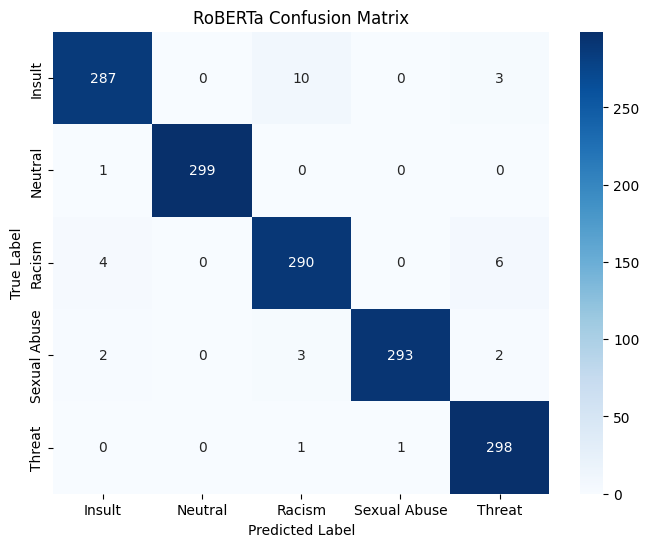

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix



cm = confusion_matrix(
    true_labels,
    predictions
)


plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Insult",
        "Neutral",
        "Racism",
        "Sexual Abuse",
        "Threat"
    ],
    yticklabels=[
        "Insult",
        "Neutral",
        "Racism",
        "Sexual Abuse",
        "Threat"
    ]
)


plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("RoBERTa Confusion Matrix")

plt.show()

EVALUATION

In [ ]:
from google.colab import files

uploaded_roberta = files.upload()

print("Upload completed!")
print("Uploaded file:", list(uploaded_roberta.keys())[0])

Saving roberta_trained_model.zip to roberta_trained_model.zip
Upload completed!
Uploaded file: roberta_trained_model.zip


In [ ]:
import zipfile
import os

roberta_zip = list(uploaded_roberta.keys())[0]
roberta_path = "./roberta_model"

with zipfile.ZipFile(roberta_zip, "r") as zip_ref:
    zip_ref.extractall(roberta_path)

print("RoBERTa model extracted successfully!")
print("Location:", roberta_path)

print("\nExtracted files:")

for root, dirs, files_list in os.walk(roberta_path):
    for file in files_list:
        print(os.path.join(root, file))

RoBERTa model extracted successfully!
Location: ./roberta_model

Extracted files:
./roberta_model/tokenizer.json
./roberta_model/tokenizer_config.json
./roberta_model/model.safetensors
./roberta_model/config.json


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

roberta_tokenizer = AutoTokenizer.from_pretrained(
    roberta_path
)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    roberta_path,
    num_labels=5
)

roberta_model.to(device)
roberta_model.eval()

print("\nRoBERTa model loaded successfully!")
print("Number of labels:", roberta_model.config.num_labels)

Device: cpu


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


RoBERTa model loaded successfully!
Number of labels: 5


In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = list(uploaded.keys())[0]

test_df_source = pd.read_csv(filename)

print("Dataset uploaded successfully!")
print("Shape:", test_df_source.shape)
print("Columns:", test_df_source.columns.tolist())

Saving Model final dataset.csv to Model final dataset.csv
Dataset uploaded successfully!
Shape: (15000, 2)
Columns: ['Sentences', 'Labels']


In [ ]:

from sklearn.model_selection import train_test_split


label_mapping = {
    0: "Insult",
    1: "Neutral",
    2: "Racism",
    3: "Sexual Abuse",
    4: "Threat"
}

train_df, temp_df = train_test_split(
    test_df_source,
    test_size=3000,
    stratify=test_df_source["Labels"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=1500,
    stratify=temp_df["Labels"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Datasets recreated successfully!")

print("\nTraining:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTest label distribution:")
print(test_df["Labels"].value_counts().sort_index())

print("\nLabel mapping:")
for number, name in label_mapping.items():
    print(f"{number} -> {name}")

Datasets recreated successfully!

Training: (12000, 2)
Validation: (1500, 2)
Testing: (1500, 2)

Test label distribution:
Labels
0    300
1    300
2    300
3    300
4    300
Name: count, dtype: int64

Label mapping:
0 -> Insult
1 -> Neutral
2 -> Racism
3 -> Sexual Abuse
4 -> Threat


In [ ]:
test_texts = test_df["Sentences"].astype(str).tolist()
test_labels = test_df["Labels"].tolist()

roberta_test_encodings = roberta_tokenizer(
    test_texts,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

roberta_test_labels = torch.tensor(test_labels)

print("RoBERTa test dataset tokenized successfully!")

print("Input IDs:",
      roberta_test_encodings["input_ids"].shape)

print("Attention Masks:",
      roberta_test_encodings["attention_mask"].shape)

print("Labels:",
      roberta_test_labels.shape)

RoBERTa test dataset tokenized successfully!
Input IDs: torch.Size([1500, 128])
Attention Masks: torch.Size([1500, 128])
Labels: torch.Size([1500])


In [ ]:

from torch.utils.data import TensorDataset, DataLoader

batch_size = 16

roberta_test_dataset = TensorDataset(
    roberta_test_encodings["input_ids"],
    roberta_test_encodings["attention_mask"],
    roberta_test_labels
)

roberta_test_loader = DataLoader(
    roberta_test_dataset,
    batch_size=batch_size,
    shuffle=False
)

roberta_predictions = []
roberta_probabilities = []
roberta_true_labels = []

with torch.no_grad():

    for input_ids, attention_mask, labels in roberta_test_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = roberta_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)

        roberta_predictions.extend(
            predictions.cpu().numpy()
        )

        roberta_probabilities.extend(
            probabilities.cpu().numpy()
        )

        roberta_true_labels.extend(
            labels.numpy()
        )

print("RoBERTa prediction completed!")

print("Predictions:", len(roberta_predictions))
print("True labels:", len(roberta_true_labels))

RoBERTa prediction completed!
Predictions: 1500
True labels: 1500


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

roberta_accuracy = accuracy_score(
    roberta_true_labels,
    roberta_predictions
)

roberta_precision = precision_score(
    roberta_true_labels,
    roberta_predictions,
    average="weighted",
    zero_division=0
)

roberta_recall = recall_score(
    roberta_true_labels,
    roberta_predictions,
    average="weighted",
    zero_division=0
)

roberta_macro_f1 = f1_score(
    roberta_true_labels,
    roberta_predictions,
    average="macro",
    zero_division=0
)

roberta_weighted_f1 = f1_score(
    roberta_true_labels,
    roberta_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 50)
print("RoBERTa TEST RESULTS")
print("=" * 50)

print(f"Accuracy       : {roberta_accuracy:.4f}")
print(f"Precision      : {roberta_precision:.4f}")
print(f"Recall         : {roberta_recall:.4f}")
print(f"Macro F1       : {roberta_macro_f1:.4f}")
print(f"Weighted F1    : {roberta_weighted_f1:.4f}")

target_names = [
    "Insult",
    "Neutral",
    "Racism",
    "Sexual Abuse",
    "Threat"
]

print("\nClassification Report:")

print(
    classification_report(
        roberta_true_labels,
        roberta_predictions,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

roberta_cm = confusion_matrix(
    roberta_true_labels,
    roberta_predictions
)

print(roberta_cm)

RoBERTa TEST RESULTS
Accuracy       : 0.9960
Precision      : 0.9960
Recall         : 0.9960
Macro F1       : 0.9960
Weighted F1    : 0.9960

Classification Report:
              precision    recall  f1-score   support

      Insult     1.0000    0.9900    0.9950       300
     Neutral     1.0000    1.0000    1.0000       300
      Racism     0.9868    0.9967    0.9917       300
Sexual Abuse     1.0000    0.9967    0.9983       300
      Threat     0.9934    0.9967    0.9950       300

    accuracy                         0.9960      1500
   macro avg     0.9960    0.9960    0.9960      1500
weighted avg     0.9960    0.9960    0.9960      1500


Confusion Matrix:
[[297   0   2   0   1]
 [  0 300   0   0   0]
 [  0   0 299   0   1]
 [  0   0   1 299   0]
 [  0   0   1   0 299]]


In [ ]:
import numpy as np

roberta_results = test_df.copy().reset_index(drop=True)

roberta_results["RoBERTa_Prediction"] = roberta_predictions

roberta_results["RoBERTa_Correct"] = (
    roberta_results["Labels"] ==
    roberta_results["RoBERTa_Prediction"]
)

roberta_probabilities_array = np.array(
    roberta_probabilities
)

for i, label_name in enumerate(target_names):

    roberta_results[
        f"RoBERTa_Prob_{label_name.replace(' ', '_')}"
    ] = roberta_probabilities_array[:, i]

roberta_results.to_csv(
    "roberta_test_predictions.csv",
    index=False
)

print("RoBERTa predictions saved successfully!")
print("File: roberta_test_predictions.csv")

print(
    "\nCorrect predictions:",
    roberta_results["RoBERTa_Correct"].sum()
)

print(
    "Incorrect predictions:",
    (~roberta_results["RoBERTa_Correct"]).sum()
)

RoBERTa predictions saved successfully!
File: roberta_test_predictions.csv

Correct predictions: 1494
Incorrect predictions: 6


In [ ]:

from google.colab import files

files.download("roberta_test_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Measure inference time

In [ ]:
!pip install -q -U "transformers==4.46.3" "tokenizers==0.20.3" "sentencepiece==0.2.0" "safetensors" "sympy>=1.13.1"

print("Packages installed. Restarting runtime to load the new versions...")
import os
os.kill(os.getpid(), 9)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 40.1 MB/s eta 0:00:00


In [ ]:
import os
import gc
import time
import shutil
import zipfile
import statistics
import warnings
from pathlib import Path

import torch

from google.colab import files
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    logging as hf_logging,
)

hf_logging.set_verbosity_error()
warnings.filterwarnings("ignore")

In [ ]:
print("=" * 60)
print("ENVIRONMENT")
print("=" * 60)

print("PyTorch:", torch.__version__)

import transformers
print("Transformers:", transformers.__version__)

print("Device: CPU")

NUM_THREADS = os.cpu_count() or 1
torch.set_num_threads(NUM_THREADS)
print(f"CPU threads used by torch: {NUM_THREADS}")

ENVIRONMENT
PyTorch: 2.11.0+cpu
Transformers: 4.46.3
Device: CPU
CPU threads used by torch: 2


In [ ]:
print("\n" + "=" * 60)
print("UPLOAD TRAINED ROBERTA MODEL")
print("=" * 60)

print("Please upload your trained RoBERTa model ZIP file.")

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No file was uploaded. Please re-run this cell and upload a ZIP.")

zip_name = next(iter(uploaded.keys()))

print("\nUploaded:", zip_name)


UPLOAD TRAINED ROBERTA MODEL
Please upload your trained RoBERTa model ZIP file.


Saving roberta_trained_model.zip to roberta_trained_model.zip

Uploaded: roberta_trained_model.zip


In [ ]:
extract_path = Path("/content/roberta_benchmark_model")

if extract_path.exists():
    shutil.rmtree(extract_path)

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Model extracted successfully.")

Model extracted successfully.


In [ ]:
candidate_dirs = []

for root, dirs, file_names in os.walk(extract_path):
    if "config.json" in file_names:
        candidate_dirs.append(Path(root))

if not candidate_dirs:
    raise FileNotFoundError(
        "Could not find config.json inside the uploaded model ZIP."
    )

if len(candidate_dirs) > 1:
    print(
        f"\nWARNING: found {len(candidate_dirs)} folders containing config.json "
        f"(e.g. multiple checkpoints). Using the shallowest path:"
    )
    for d in candidate_dirs:
        print("  -", d)

model_path = min(candidate_dirs, key=lambda p: len(p.parts))

print("\nModel directory:")
print(model_path)


Model directory:
/content/roberta_benchmark_model


In [ ]:
model_size_bytes = 0

for root, dirs, file_names in os.walk(model_path):
    for file_name in file_names:
        file_path = Path(root) / file_name
        model_size_bytes += file_path.stat().st_size

model_size_mb = model_size_bytes / (1024 ** 2)
model_size_gb = model_size_bytes / (1024 ** 3)

print("\nModel size:")
print(f"{model_size_mb:.2f} MB")
print(f"{model_size_gb:.4f} GB")


Model size:
478.92 MB
0.4677 GB


In [ ]:
print("\n" + "=" * 60)
print("LOADING TOKENIZER")
print("=" * 60)

tokenizer_start = time.perf_counter()

tokenizer = AutoTokenizer.from_pretrained(str(model_path))

tokenizer_end = time.perf_counter()
tokenizer_time = tokenizer_end - tokenizer_start

print("Tokenizer loaded successfully.")


LOADING TOKENIZER
Tokenizer loaded successfully.


In [ ]:
print("\n" + "=" * 60)
print("LOADING MODEL")
print("=" * 60)

device = torch.device("cpu")

model_start = time.perf_counter()

model = AutoModelForSequenceClassification.from_pretrained(str(model_path))
model.to(device)
model.eval()

model_end = time.perf_counter()
model_loading_time = model_end - model_start

print("Model loaded successfully.")


LOADING MODEL


Model loaded successfully.


In [ ]:
total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("\n" + "=" * 60)
print("MODEL INFORMATION")
print("=" * 60)

print(f"Total parameters: {total_parameters:,} (~{total_parameters / 1e6:.1f}M)")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Number of labels: {model.config.num_labels}")


MODEL INFORMATION
Total parameters: 124,649,477 (~124.6M)
Trainable parameters: 124,649,477
Number of labels: 5


In [ ]:
test_sentence = (
    "This is a test sentence for measuring "
    "the inference time of the RoBERTa classifier."
)

inputs = tokenizer(
    test_sentence,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=128,
)

inputs = {key: value.to(device) for key, value in inputs.items()}

In [ ]:
print("\n" + "=" * 60)
print("WARMING UP MODEL")
print("=" * 60)

with torch.inference_mode():
    for _ in range(10):
        model(**inputs)

print("Warm-up completed.")


WARMING UP MODEL
Warm-up completed.


In [ ]:
print("\n" + "=" * 60)
print("MEASURING CPU INFERENCE TIME")
print("=" * 60)


gc.collect()

number_of_runs = 100
inference_times = []

with torch.inference_mode():
    for _ in range(number_of_runs):
        start_time = time.perf_counter()
        model(**inputs)
        end_time = time.perf_counter()

        elapsed = (end_time - start_time) * 1000
        inference_times.append(elapsed)


MEASURING CPU INFERENCE TIME


In [ ]:
average_inference_time = statistics.mean(inference_times)
minimum_inference_time = min(inference_times)
maximum_inference_time = max(inference_times)
standard_deviation = (
    statistics.stdev(inference_times) if len(inference_times) > 1 else 0.0
)

In [ ]:
print("\n")
print("=" * 60)
print("FINAL ROBERTA BENCHMARK RESULTS")
print("=" * 60)

print(f"Model size          : {model_size_mb:.2f} MB")
print(f"Total parameters    : {total_parameters:,}")
print(f"Model loading time  : {model_loading_time:.2f} seconds")
print(f"Tokenizer load time : {tokenizer_time:.2f} seconds")
print(f"Average inference   : {average_inference_time:.2f} ms")
print(f"Minimum inference   : {minimum_inference_time:.2f} ms")
print(f"Maximum inference   : {maximum_inference_time:.2f} ms")
print(f"Std deviation       : {standard_deviation:.2f} ms")
print(f"CPU threads         : {NUM_THREADS}")
print(f"Device              : {device}")
print("=" * 60)



FINAL ROBERTA BENCHMARK RESULTS
Model size          : 478.92 MB
Total parameters    : 124,649,477
Model loading time  : 18.87 seconds
Tokenizer load time : 0.50 seconds
Average inference   : 262.63 ms
Minimum inference   : 121.08 ms
Maximum inference   : 934.43 ms
Std deviation       : 172.61 ms
CPU threads         : 2
Device              : cpu
